Dropping 1 triads with excluded pre-FMT samples
Dropping 0 error rows from 'Unrelated (within dataset)' belonging to []

Kruskal-Wallis H = 9671.275, p = 0.000e+00
  n(Post-FMT × Donor) = 529
  n(Pre-FMT × Post-FMT) = 381
  n(Pre-FMT × Donor) = 329
  n(Unrelated (within dataset)) = 9781
  n(Unrelated (across datasets)) = 219109

Dunn's post-hoc pairwise comparisons (BH-adjusted):
                     group1                       group2   n1     n2  median1  median2         z    p_raw    p_adj
          Post-FMT ×\nDonor             Pre-FMT ×\nDonor  529    329 0.518519 0.032258 17.591406 0.000000 0.000000
          Post-FMT ×\nDonor  Unrelated\n(within dataset)  529   9781 0.518519 0.032258 28.519897 0.000000 0.000000
          Post-FMT ×\nDonor Unrelated\n(across datasets)  529 219109 0.518519 0.000000 47.240826 0.000000 0.000000
        Pre-FMT ×\nPost-FMT             Pre-FMT ×\nDonor  381    329 0.764706 0.032258 16.557061 0.000000 0.000000
        Pre-FMT ×\nPost-FMT Unrelated\n(ac

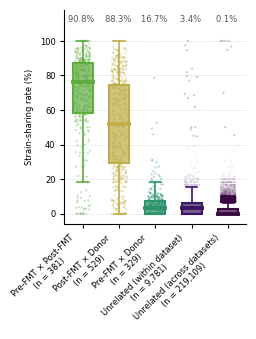


  Unrelated (within dataset)  —  sharing rate > 30%  (26 pairs)
sample_id_1 role_1          dataset_1 sample_id_2 role_2          dataset_2  sharing_rate
SRR14868464    pre    WoodworthM_2023 SRR14868472    pre    WoodworthM_2023      1.000000
SRR34514453    pre    FernandesR_2026 SRR34514442    pre    FernandesR_2026      0.974576
    16_0_S3    pre         GollR_2020     11_6_S8   post         GollR_2020      0.947368
    31_0_S9    pre         GollR_2020     25_6_S4   post         GollR_2020      0.839080
 SRS8258561   post      WatsonAR_2021  SRS8258565    pre      WatsonAR_2021      0.818182
    31_6_S2   post         GollR_2020     30_0_S8    pre         GollR_2020      0.796296
SRR33578147   post      SuQ_2026_rCDI SRR33578126    pre      SuQ_2026_rCDI      0.791667
SRR14868464    pre    WoodworthM_2023 SRR14868466   post    WoodworthM_2023      0.769231
 SRS8258585   post      WatsonAR_2021  SRS8258565    pre      WatsonAR_2021      0.692308
SRR14321970   post           NgS_20

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

plt.rcParams["svg.fonttype"] = "none"

# ============================================================
# ---------- PATHS — edit these ----------
# ============================================================
TRIADS_PATH   = '/shares/CIBIO-Storage/CM/scratch/users/thomas.barbazuk/meta-strain/analysis/doser_results_for_ssr.csv'
PAIRWISE_PATH = '/shares/CIBIO-Storage/CM/scratch/users/thomas.barbazuk/meta-strain/strain_share_newrun_June26/results/strainphlan/pairwise_sharing_allRaxml.tsv'

triads   = pd.read_csv(TRIADS_PATH)
pairwise = pd.read_csv(PAIRWISE_PATH, sep='\t')

# Drop entire triads containing excluded pre-FMT samples
EXCLUDE_PRE_SAMPLES = [
    "SRR14871871",
    "SRR14872202",
    "SRR14872194",
]

exclude_mask = triads["pre_fmt_id"].isin(EXCLUDE_PRE_SAMPLES)

print(f"Dropping {exclude_mask.sum()} triads with excluded pre-FMT samples")

triads = triads.loc[~exclude_mask].copy()

# ============================================================
# ---------- triad-based SSR ----------
# ============================================================
def parse_sgbs(x):
    if pd.isna(x): return set()
    return set(s.strip() for s in str(x).split(",") if s.strip())

df = triads.copy()
donor_sets = df["donor_sgbs"].apply(parse_sgbs)
pre_sets   = df["pre_sgbs"].apply(parse_sgbs)
post_sets  = df["post_sgbs"].apply(parse_sgbs)

df["den_pre_donor"]  = [len(p & d) for p, d in zip(pre_sets,  donor_sets)]
df["den_pre_post"]   = [len(p & q) for p, q in zip(pre_sets,  post_sets)]
df["den_post_donor"] = [len(q & d) for q, d in zip(post_sets, donor_sets)]

base = df[["display_dataset", "donor_id", "pre_fmt_id", "post_fmt_id"]].copy()

def make_arm(label, numerator_col, denominator_col):
    arm = base.copy()
    arm["comparison"]   = label
    arm["numerator"]    = df[numerator_col]
    arm["denominator"]  = df[denominator_col]
    # raw number of shared strains for this comparison (used for the ">=5 strains" stat)
    arm["shared_count"] = df[numerator_col]
    return arm

final_df = pd.concat([
    make_arm("Post-FMT ×\nDonor",   "n_shared_donor_post", "den_post_donor"),
    make_arm("Pre-FMT ×\nPost-FMT", "n_shared_post_pre",   "den_pre_post"),
    make_arm("Pre-FMT ×\nDonor",    "n_shared_donor_pre",  "den_pre_donor"),
], ignore_index=True)

plot_df = final_df[final_df["denominator"] >= 10].copy()
plot_df["sharing_rate"] = plot_df["numerator"] / plot_df["denominator"]
plot_df = plot_df[["display_dataset", "comparison", "sharing_rate", "shared_count"]]

# ============================================================
# ---------- pairwise-based unrelated controls ----------
# ============================================================
pre_lookup  = df[["pre_fmt_id",  "display_dataset"]].drop_duplicates().rename(columns={"pre_fmt_id":  "sample_id"})
pre_lookup["role"] = "pre"
post_lookup = df[["post_fmt_id", "display_dataset"]].drop_duplicates().rename(columns={"post_fmt_id": "sample_id"})
post_lookup["role"] = "post"

sample_meta      = pd.concat([pre_lookup, post_lookup]).drop_duplicates(subset="sample_id")
sample_meta_dict = sample_meta.set_index("sample_id")[["display_dataset", "role"]].to_dict("index")

related_pairs = set()
for _, row in df.iterrows():
    for a, b in [("pre_fmt_id","post_fmt_id"), ("pre_fmt_id","donor_id"), ("post_fmt_id","donor_id")]:
        related_pairs.add((row[a], row[b]))
        related_pairs.add((row[b], row[a]))

pw = pairwise.dropna(subset=["strain_sharing_rate"]).copy()
pw = pw[pw["sample_id_1"].isin(sample_meta_dict) & pw["sample_id_2"].isin(sample_meta_dict)].copy()

pw["dataset_1"] = pw["sample_id_1"].map(lambda x: sample_meta_dict[x]["display_dataset"])
pw["role_1"]    = pw["sample_id_1"].map(lambda x: sample_meta_dict[x]["role"])
pw["dataset_2"] = pw["sample_id_2"].map(lambda x: sample_meta_dict[x]["display_dataset"])
pw["role_2"]    = pw["sample_id_2"].map(lambda x: sample_meta_dict[x]["role"])

pw["is_related"] = [(r.sample_id_1, r.sample_id_2) in related_pairs for r in pw.itertuples()]
pw = pw[~pw["is_related"]].copy()

pw = pw[pw["n_shared_species"] >= 10].copy()

# raw shared-strain count for the pairwise table
SHARED_COUNT_COL = "n_shared_strains"


def pairwise_arm(label, same_dataset):
    parts = []
    for role1, role2 in [("pre", "pre"), ("pre", "post"), ("post", "pre")]:
        mask = (pw["role_1"] == role1) & (pw["role_2"] == role2)
        if same_dataset:
            mask &= (pw["dataset_1"] == pw["dataset_2"])
        else:
            mask &= (pw["dataset_1"] != pw["dataset_2"])
        parts.append(pw[mask])
    sub = pd.concat(parts).drop_duplicates()
    sub = sub.copy()
    sub["comparison"]      = label
    sub["sharing_rate"]    = sub["strain_sharing_rate"]
    sub["shared_count"]    = sub[SHARED_COUNT_COL]
    sub["display_dataset"] = sub["dataset_1"]
    return sub[["display_dataset", "comparison", "sharing_rate", "shared_count",
                "sample_id_1", "sample_id_2", "role_1", "role_2",
                "dataset_1", "dataset_2"]]

# ============================================================
# --- keep full pairwise arms (with IDs) for investigation ---
# ============================================================
within_arm  = pairwise_arm("Unrelated\n(within dataset)", same_dataset=True)
across_arm  = pairwise_arm("Unrelated\n(across datasets)", same_dataset=False)

all_plot = pd.concat([
    plot_df,
    within_arm[["display_dataset", "comparison", "sharing_rate", "shared_count"]],
    across_arm[["display_dataset", "comparison", "sharing_rate", "shared_count"]],
], ignore_index=True)

# ============================================================
# ---------- drop known-error outliers ----------
# NooijS_2024 and WoodworthM_2023 unrelated *within-dataset* comparisons
# have been identified as erroneous — drop them entirely.
# ============================================================
ERROR_DATASETS = []
error_mask = (
    (all_plot["comparison"] == "Unrelated\n(within dataset)") &
    (all_plot["display_dataset"].isin(ERROR_DATASETS))
)
print(f"Dropping {error_mask.sum()} error rows from 'Unrelated (within dataset)' "
      f"belonging to {ERROR_DATASETS}")
all_plot = all_plot[~error_mask].copy()

# ============================================================
# ---------- statistical tests: Kruskal-Wallis + Dunn's (manual) ----------
# ============================================================
from scipy import stats
from statsmodels.stats.multitest import multipletests
from itertools import combinations

def dunn_test(df, val_col, group_col, p_adjust="fdr_bh"):
    df = df.copy()
    groups = df[group_col].unique()
    all_vals = df[val_col].values
    df["_rank"] = stats.rankdata(all_vals)
    N = len(df)

    _, counts = np.unique(all_vals, return_counts=True)
    tie_term = np.sum(counts**3 - counts) / (12 * (N - 1))

    group_stats = df.groupby(group_col)["_rank"].agg(["mean", "count"])
    medians = df.groupby(group_col)[val_col].median()

    results = []
    for g1, g2 in combinations(groups, 2):
        R1, n1 = group_stats.loc[g1, "mean"], group_stats.loc[g1, "count"]
        R2, n2 = group_stats.loc[g2, "mean"], group_stats.loc[g2, "count"]
        se = np.sqrt((N * (N + 1) / 12 - tie_term) * (1 / n1 + 1 / n2))
        z = (R1 - R2) / se
        p = 2 * (1 - stats.norm.cdf(abs(z)))
        results.append((g1, g2, n1, n2, medians[g1], medians[g2], z, p))

    res_df = pd.DataFrame(results, columns=["group1", "group2", "n1", "n2",
                                            "median1", "median2", "z", "p_raw"])
    res_df["p_adj"] = multipletests(res_df["p_raw"], method=p_adjust)[1]
    return res_df.sort_values("p_adj").reset_index(drop=True)


# ---- run Kruskal-Wallis omnibus test ----
groups_dict = {
    comp: all_plot.loc[all_plot["comparison"] == comp, "sharing_rate"].dropna().values
    for comp in all_plot["comparison"].unique()
}
groups_dict = {k: v for k, v in groups_dict.items() if len(v) > 0}

kw_stat, kw_p = stats.kruskal(*groups_dict.values())
print(f"\nKruskal-Wallis H = {kw_stat:.3f}, p = {kw_p:.3e}")
for k, v in groups_dict.items():
    print(f"  n({k.replace(chr(10), ' ')}) = {len(v)}")

# ---- run Dunn's post-hoc (Holm-adjusted) ----
dunn_res = dunn_test(
    all_plot.dropna(subset=["sharing_rate"]),
    val_col="sharing_rate",
    group_col="comparison",
    p_adjust="fdr_bh"
)
print("\nDunn's post-hoc pairwise comparisons (BH-adjusted):")
print(dunn_res.to_string(index=False))

dunn_res.to_csv("dunn_posthoc_pvalues.tsv", sep="\t", index=False)
print(f"\nSaved Dunn's post-hoc results to dunn_posthoc_pvalues.tsv")

PD, PP, PRD = "Post-FMT ×\nDonor", "Pre-FMT ×\nPost-FMT", "Pre-FMT ×\nDonor"
UW, UA = "Unrelated\n(within dataset)", "Unrelated\n(across datasets)"

def report(a, b):
    r = dunn_res[((dunn_res.group1 == a) & (dunn_res.group2 == b)) |
                 ((dunn_res.group1 == b) & (dunn_res.group2 == a))].iloc[0]
    ma = r.median1 if r.group1 == a else r.median2
    mb = r.median2 if r.group1 == a else r.median1
    p = "p < 0.001" if r.p_adj < 0.001 else f"p = {r.p_adj:.3f}"
    print(f"{a!r} (median {ma:.3f}) vs {b!r} (median {mb:.3f}): {p}  [raw p = {r.p_raw:.2e}]")

df_kw = len(groups_dict) - 1
print(f"\nKruskal-Wallis H({df_kw}) = {kw_stat:.1f}, p = {kw_p:.2e}")
for k, v in groups_dict.items():
    print(f"  {k.replace(chr(10), ' ')}: n = {len(v)}, median = {np.median(v):.3f}")

print("\n--- Numbers for the results paragraph ---")
report(PD, PRD)   # post×donor > pre×donor
report(PD, UW); report(PD, UA)
report(PP, UW); report(PP, UA)
report(PD, PP)    # the "did not differ" comparison
report(PRD, PD); report(PRD, PP)
report(PRD, UW)   # "marginally elevated" comparison
report(PRD, UA)
# ============================================================
# ---------- order columns by descending mean ----------
# ============================================================
mean_order = (
    all_plot.groupby("comparison")["sharing_rate"]
    .mean()
    .sort_values(ascending=False)
    .index.tolist()
)

palette = {
    "Post-FMT ×\nDonor":            "#BFAE48",  # deep teal-green
    "Pre-FMT ×\nPost-FMT":          "#5FAD41",  # warm gold
    "Pre-FMT ×\nDonor":             "#2D936C",  # steel blue
    "Unrelated\n(within dataset)":  "#391463",  # muted rose/red
    "Unrelated\n(across datasets)": "#3A0842",  # neutral gray
}

# ============================================================
# ---------- plot ----------
# ============================================================
np.random.seed(42)
fig, ax = plt.subplots(
    figsize=(55/ 25.4, 85/ 25.4)
)

for i, comp in enumerate(mean_order):
    sub = all_plot.loc[all_plot["comparison"] == comp, ["sharing_rate", "shared_count"]].dropna(subset=["sharing_rate"])
    data = sub["sharing_rate"].values
    if len(data) == 0:
        continue

    q1, median, q3 = np.percentile(data, [25, 50, 75])
    iqr = q3 - q1
    whisker_lo = max(data[data >= q1 - 1.5 * iqr].min(), data.min())
    whisker_hi = min(data[data <= q3 + 1.5 * iqr].max(), data.max())
    color      = palette[comp]
    box_w      = 0.55

    # filled box
    ax.add_patch(FancyBboxPatch(
        (i - box_w/2, q1), box_w, q3 - q1,
        boxstyle="square,pad=0",
        linewidth=1.4, edgecolor=color,
        facecolor=color, alpha=0.7, zorder=2
    ))
    # box border
    ax.plot(
        [i-box_w/2, i+box_w/2, i+box_w/2, i-box_w/2, i-box_w/2],
        [q1, q1, q3, q3, q1],
        color=color, linewidth=1.5, zorder=3
    )
    # median
    ax.plot([i-box_w/2, i+box_w/2], [median, median],
            color=color, linewidth=2.8, zorder=4)
    # whiskers
    ax.plot([i, i], [q3, whisker_hi], color=color, linewidth=1.2, zorder=2)
    ax.plot([i, i], [q1, whisker_lo], color=color, linewidth=1.2, zorder=2)
    # caps
    cap_w = box_w * 0.28
    ax.plot([i-cap_w, i+cap_w], [whisker_hi, whisker_hi], color=color, linewidth=1.2)
    ax.plot([i-cap_w, i+cap_w], [whisker_lo, whisker_lo], color=color, linewidth=1.2)

    # For the two "Unrelated" arms: show ALL points above the whiskers, but the band
    # just above the whiskers is very dense/noisy, so those points are drawn smaller,
    # fainter, and behind the box (low zorder) to de-emphasize them. Points that clear
    # the 40% threshold are true outliers and are drawn clearly on top.
    # "Across datasets" has ~300k points vs a much smaller "within dataset" arm, so it
    # needs much more aggressive muting (tinier/fainter points, plus subsampling so we're
    # not literally rendering hundreds of thousands of overlapping dots).
    UNRELATED_ARMS = ["Unrelated\n(within dataset)", "Unrelated\n(across datasets)"]
    OUTLIER_THRESHOLD = 0.4

    NOISY_BAND_STYLE = {
        "Unrelated\n(within dataset)":  {"alpha": 0.07, "s": 1.5,   "max_points": None},
        "Unrelated\n(across datasets)": {"alpha": 0.07, "s": 1.5, "max_points": 4000},
    }

    if comp in UNRELATED_ARMS:
        above_whisker = data > whisker_hi
        noisy_band    = above_whisker & (data <= OUTLIER_THRESHOLD)
        true_outlier  = data > OUTLIER_THRESHOLD

        style = NOISY_BAND_STYLE[comp]
        noisy_data = data[noisy_band]
        if style["max_points"] is not None and len(noisy_data) > style["max_points"]:
            noisy_data = np.random.choice(noisy_data, size=style["max_points"], replace=False)
        if len(noisy_data) > 0:
            jitter_noisy = np.random.uniform(-box_w * 0.38, box_w * 0.38, size=len(noisy_data))
            ax.scatter(i + jitter_noisy, noisy_data, color=color, alpha=style["alpha"], s=style["s"],
                       zorder=0, edgecolors="none")

        outlier_data = data[true_outlier]
        if len(outlier_data) > 0:
            jitter_out = np.random.uniform(-box_w * 0.38, box_w * 0.38, size=len(outlier_data))
            ax.scatter(i + jitter_out, outlier_data, color=color, alpha=0.25, s=2.5,
                       zorder=1, edgecolors="none")
    else:
        jitter = np.random.uniform(-box_w * 0.38, box_w * 0.38, size=len(data))
        ax.scatter(i + jitter, data, color=color, alpha=0.35, s=2.5, zorder=1, edgecolors="none")

    # % of comparisons sharing at least 5 strains, at top of plot area
    shared_counts = sub["shared_count"].dropna().values
    if len(shared_counts) > 0:
        pct_ge5 = (shared_counts >= 5).sum() / len(shared_counts) * 100
        label_txt = f"{pct_ge5:.1f}% "
        # \u2265 5 strains"
    else:
        label_txt = "n/a"
    ax.text(i, 1.10, label_txt,
            ha="center", va="bottom", fontsize=6, color="#555555")

# axes
xticklabels = []

for comp in mean_order:
    n = (all_plot["comparison"] == comp).sum()
    xticklabels.append(f"{comp.replace(chr(10), ' ')}\n(n = {n:,})")

ax.set_xticks(range(len(mean_order)))
ax.set_xticklabels(
    xticklabels,
    fontsize=6,
    rotation=45,
    ha="right",
    multialignment="center"
)
ax.set_ylabel("Strain-sharing rate (%)", fontsize=6)
ax.set_xlabel("")
ax.set_ylim(-0.06, 1.18)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x*100:.0f}"))
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_linewidth(0.8)
ax.tick_params(axis="both", which="major", labelsize=6, length=3, width=0.8)
ax.yaxis.grid(True, linestyle="--", linewidth=0.5, alpha=0.4, zorder=0)
ax.set_axisbelow(True)

# plt.tight_layout()
# plt.savefig("strain_sharing_boxplot.pdf", dpi=300, bbox_inches="tight")
# plt.savefig("strain_sharing_boxplot.svg", bbox_inches="tight")

plt.subplots_adjust(
    left=0.14,
    right=0.98,
    bottom=0.28,
    top=0.92
)

plt.savefig(
    "strain_sharing_boxplot.svg",
    format="svg",
    bbox_inches=None,
    pad_inches=0
)

plt.show()

# ============================================================
# ---------- print high-sharing unrelated pairs (> 30%) ------
# ============================================================
HIGH_THRESHOLD = 0.30

for label, arm in [("Unrelated (within dataset)", within_arm),
                   ("Unrelated (across datasets)", across_arm)]:
    high = arm[arm["sharing_rate"] > HIGH_THRESHOLD].copy()
    high = high.sort_values("sharing_rate", ascending=False)
    print(f"\n{'='*60}")
    print(f"  {label}  —  sharing rate > {HIGH_THRESHOLD*100:.0f}%  ({len(high)} pairs)")
    print(f"{'='*60}")
    if high.empty:
        print("  (none)")
    else:
        print(high[[
            "sample_id_1", "role_1", "dataset_1",
            "sample_id_2", "role_2", "dataset_2",
            "sharing_rate"
        ]].to_string(index=False))

# also save to TSV for easier inspection
high_within = within_arm[within_arm["sharing_rate"] > HIGH_THRESHOLD].sort_values("sharing_rate", ascending=False)
high_across = across_arm[across_arm["sharing_rate"] > HIGH_THRESHOLD].sort_values("sharing_rate", ascending=False)
high_all = pd.concat([high_within, high_across], ignore_index=True)
high_all.to_csv("high_sharing_unrelated_pairs.tsv", sep="\t", index=False)
print(f"\nSaved {len(high_all)} high-sharing pairs to high_sharing_unrelated_pairs.tsv")

Post×Donor: n=529, mean=0.511, median=0.519, IQR=0.293-0.742, <10%: 8.7%, >90%: 5.9%
Pre×Post  : n=381, mean=0.689, median=0.765, IQR=0.583-0.872, <10%: 6.3%, >90%: 15.0%

P(post×donor > pre×post) = 0.304 (0.5 = no dominance), Mann-Whitney p = 6.6e-24
KS test (any distribution difference): D=0.331, p = 5.41e-22


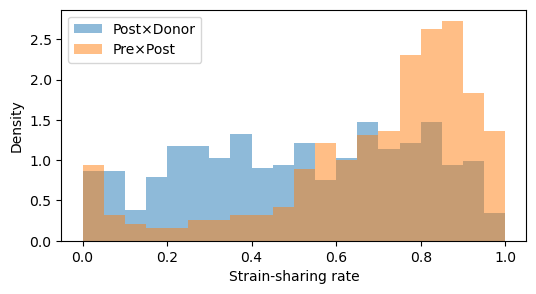


Paired triads (pass filter in both arms): 363
Median paired difference (pre×post minus post×donor): 0.345
Medians in this subset: pre×post 0.762, post×donor 0.391
Wilcoxon signed-rank p = 3.78e-25
Spearman rho between arms: -0.561


In [13]:
from scipy import stats
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

PD, PP = "Post-FMT ×\nDonor", "Pre-FMT ×\nPost-FMT"

a = all_plot.loc[all_plot.comparison == PD, "sharing_rate"].dropna().values
b = all_plot.loc[all_plot.comparison == PP, "sharing_rate"].dropna().values

# ---- 1. Shape summary ----
def summ(name, x):
    q = np.percentile(x, [25, 50, 75])
    print(f"{name}: n={len(x)}, mean={x.mean():.3f}, median={q[1]:.3f}, "
          f"IQR={q[0]:.3f}-{q[2]:.3f}, "
          f"<10%: {(x < 0.10).mean():.1%}, >90%: {(x > 0.90).mean():.1%}")
summ("Post×Donor", a)
summ("Pre×Post  ", b)

# ---- 2. Why the rank test sees no difference ----
u = stats.mannwhitneyu(a, b, alternative="two-sided")
print(f"\nP(post×donor > pre×post) = {u.statistic / (len(a)*len(b)):.3f} "
      f"(0.5 = no dominance), Mann-Whitney p = {u.pvalue:.3g}")
ks = stats.ks_2samp(a, b)
print(f"KS test (any distribution difference): D={ks.statistic:.3f}, p = {ks.pvalue:.3g}")

# ---- 3. Look at the shapes ----
fig, ax = plt.subplots(figsize=(6, 3))
bins = np.linspace(0, 1, 21)
ax.hist(a, bins=bins, alpha=0.5, density=True, label="Post×Donor")
ax.hist(b, bins=bins, alpha=0.5, density=True, label="Pre×Post")
ax.set_xlabel("Strain-sharing rate"); ax.set_ylabel("Density"); ax.legend()
plt.show()

# ---- 4. Paired comparison within triads ----
keys = ["display_dataset", "donor_id", "pre_fmt_id", "post_fmt_id"]
f = final_df[final_df.denominator >= 10].copy()
f["rate"] = f.numerator / f.denominator
wide = (f[f.comparison.isin([PD, PP])]
        .pivot_table(index=keys, columns="comparison", values="rate", aggfunc="first")
        .dropna())
d = wide[PP] - wide[PD]
w = stats.wilcoxon(wide[PP], wide[PD])
print(f"\nPaired triads (pass filter in both arms): {len(wide)}")
print(f"Median paired difference (pre×post minus post×donor): {d.median():.3f}")
print(f"Medians in this subset: pre×post {wide[PP].median():.3f}, post×donor {wide[PD].median():.3f}")
print(f"Wilcoxon signed-rank p = {w.pvalue:.3g}")
print(f"Spearman rho between arms: {stats.spearmanr(wide[PP], wide[PD])[0]:.3f}")

In [5]:
xticklabels = []

for comp in mean_order:
    n = (all_plot["comparison"] == comp).sum()
    xticklabels.append(f"{comp}\n(n = {n:,})")

ax.set_xticks(range(len(mean_order)))
ax.set_xticklabels(xticklabels, fontsize=6)

[Text(0, 0, 'Pre-FMT ×\nPost-FMT\n(n = 380)'),
 Text(1, 0, 'Post-FMT ×\nDonor\n(n = 527)'),
 Text(2, 0, 'Pre-FMT ×\nDonor\n(n = 327)'),
 Text(3, 0, 'Unrelated\n(within dataset)\n(n = 9,653)'),
 Text(4, 0, 'Unrelated\n(across datasets)\n(n = 216,925)')]